Завдання 1

Імпорт бібліотек і завантаження датасету

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

iris = load_iris()

X_iris = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

print("Перші 5 рядків датасету Iris:")
display(X_iris.head())

Перші 5 рядків датасету Iris:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Стандартизація даних

In [2]:
scaler_iris = StandardScaler()

X_iris_scaled = scaler_iris.fit_transform(X_iris)

print("Розмір датасету:", X_iris.shape)
print("Кількість ознак:", X_iris.shape[1])
print("Дані успішно стандартизовано.")

Розмір датасету: (150, 4)
Кількість ознак: 4
Дані успішно стандартизовано.


Визначення кількості кластерів методом ліктя

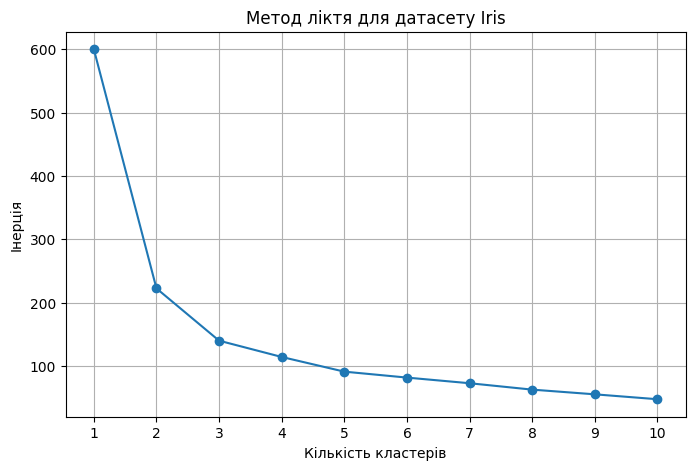

In [3]:
inertia_iris = []

K = range(1, 11)

for k in K:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_iris_scaled)
    inertia_iris.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(K), inertia_iris, marker='o')

plt.title("Метод ліктя для датасету Iris")
plt.xlabel("Кількість кластерів")
plt.ylabel("Інерція")
plt.xticks(list(K))
plt.grid(True)
plt.show()

Визначення кількості кластерів методом силуетів

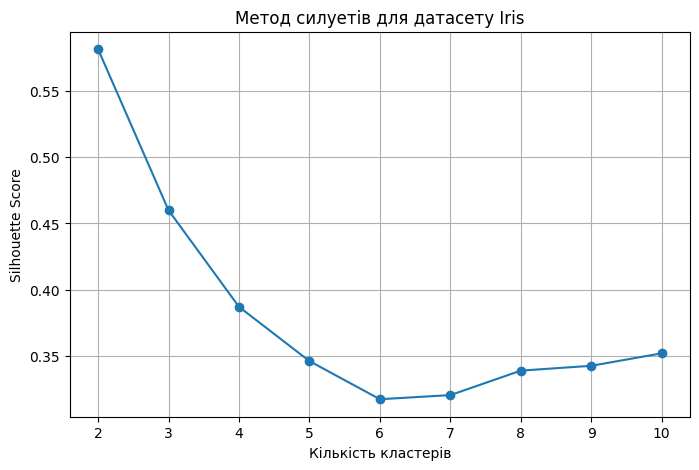

Оптимальна кількість кластерів за методом силуетів: 2


In [4]:
silhouette_scores_iris = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_iris_scaled)

    score = silhouette_score(X_iris_scaled, labels)
    silhouette_scores_iris.append(score)

plt.figure(figsize=(8, 5))
plt.plot(
    range(2, 11),
    silhouette_scores_iris,
    marker='o'
)

plt.title("Метод силуетів для датасету Iris")
plt.xlabel("Кількість кластерів")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

best_k_iris = range(2, 11)[
    np.argmax(silhouette_scores_iris)
]

print("Оптимальна кількість кластерів за методом силуетів:",
      best_k_iris)

Кластеризація та візуалізація

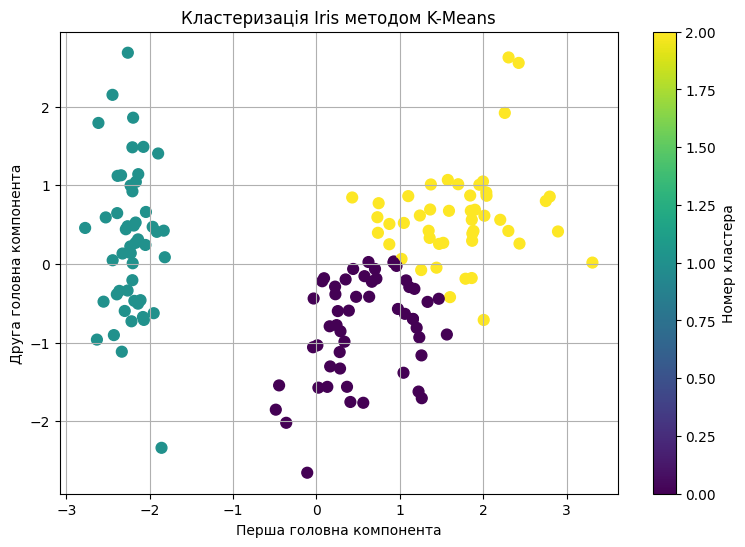

Кількість об'єктів у кожному кластері:
0    53
1    50
2    47
Name: count, dtype: int64


In [5]:
optimal_k_iris = 3

kmeans_iris = KMeans(
    n_clusters=optimal_k_iris,
    random_state=42,
    n_init=10
)

clusters_iris = kmeans_iris.fit_predict(X_iris_scaled)

pca_iris = PCA(n_components=2)

X_iris_pca = pca_iris.fit_transform(X_iris_scaled)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_iris_pca[:, 0],
    X_iris_pca[:, 1],
    c=clusters_iris,
    cmap='viridis',
    s=60
)

plt.title("Кластеризація Iris методом K-Means")
plt.xlabel("Перша головна компонента")
plt.ylabel("Друга головна компонента")
plt.colorbar(scatter, label="Номер кластера")
plt.grid(True)
plt.show()

print("Кількість об'єктів у кожному кластері:")
print(pd.Series(clusters_iris).value_counts().sort_index())

Висновок: У ході виконання першого завдання було завантажено датасет Iris, який містить чотири числові характеристики квітів. Дані стандартизовано для забезпечення коректної роботи алгоритму кластеризації K-Means.

Для визначення оптимальної кількості кластерів використано метод ліктя та метод силуетів. Метод ліктя дає змогу оцінити зміну внутрішньокластерної інерції, а метод силуетів — якість розділення кластерів.

За допомогою алгоритму K-Means виконано кластеризацію даних. Для візуалізації результатів застосовано метод головних компонент PCA, який дозволяє представити багатовимірні дані у двовимірному просторі.

У результаті отримано графічне представлення кластерів, що дає змогу оцінити їх розташування та ступінь розділення. Остаточний висновок щодо оптимальної кількості кластерів необхідно зробити на основі побудованих графіків і розрахованих значень силуетів.

Завдання 2

Завантаження датасету

In [6]:
from sklearn.datasets import load_wine

wine = load_wine()

df = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

df['target'] = wine.target

print("Перші 5 рядків датасету Wine:")
display(df.head())

Перші 5 рядків датасету Wine:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


Розмір датасету та типи даних

In [7]:
print("Розмір датасету:")
print(df.shape)

print("\nТипи даних:")
print(df.dtypes)

print("\nІнформація про датасет:")
df.info()

Розмір датасету:
(178, 14)

Типи даних:
alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
dtype: object

Інформація про датасет:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash            

Перевірка пропущених значень

In [8]:
print("Кількість пропущених значень у кожному стовпці:")
print(df.isnull().sum())

for column in df.columns:
    if df[column].isnull().any():
        df[column] = df[column].fillna(df[column].mean())

print("\nКількість пропущених значень після обробки:")
print(df.isnull().sum())

Кількість пропущених значень у кожному стовпці:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64

Кількість пропущених значень після обробки:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline   

Перевірка та видалення дублікатів

In [9]:
print("Кількість дублікатів до видалення:",
      df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)

print("Кількість дублікатів після видалення:",
      df.duplicated().sum())

print("Розмір датасету після очищення:", df.shape)

Кількість дублікатів до видалення: 0
Кількість дублікатів після видалення: 0
Розмір датасету після очищення: (178, 14)


Описова статистика

In [10]:
print("Описова статистика:")
display(df.describe())

Описова статистика:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


Визначення типу задачі

In [11]:
print("Кількість класів:", df['target'].nunique())

print("\nКількість об'єктів кожного класу:")
print(df['target'].value_counts().sort_index())

print("\nТип задачі: класифікація")

Кількість класів: 3

Кількість об'єктів кожного класу:
target
0    59
1    71
2    48
Name: count, dtype: int64

Тип задачі: класифікація


Підготовка даних до машинного навчання

In [12]:
from sklearn.model_selection import train_test_split

X_wine = df.drop(columns=['target'])
y_wine = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X_wine,
    y_wine,
    test_size=0.2,
    random_state=42,
    stratify=y_wine
)

print("Кількість рядків у навчальній вибірці:", len(X_train))
print("Кількість рядків у тестовій вибірці:", len(X_test))

Кількість рядків у навчальній вибірці: 142
Кількість рядків у тестовій вибірці: 36


Побудова трьох моделей класифікації

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000))
    ]),

    "Random Forest": RandomForestClassifier(
        random_state=42
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC())
    ])
}

print("Створено три моделі класифікації.")

Створено три моделі класифікації.


Підбір оптимальних параметрів

In [14]:
from sklearn.model_selection import GridSearchCV

param_grids = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100]
    },

    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [None, 5, 10],
        "min_samples_split": [2, 5]
    },

    "SVM": {
        "model__C": [0.1, 1, 10, 100],
        "model__kernel": ["linear", "rbf"]
    }
}

best_models = {}
results = []

for name, model in models.items():
    print(f"\nПідбір параметрів: {name}")

    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        cv=5,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    best_models[name] = grid.best_estimator_

    print("Найкращі параметри:", grid.best_params_)
    print("Найкраща середня CV accuracy:", round(grid.best_score_, 4))


Підбір параметрів: Logistic Regression
Найкращі параметри: {'model__C': 0.1}
Найкраща середня CV accuracy: 0.9931

Підбір параметрів: Random Forest
Найкращі параметри: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}
Найкраща середня CV accuracy: 0.9862

Підбір параметрів: SVM
Найкращі параметри: {'model__C': 0.1, 'model__kernel': 'linear'}
Найкраща середня CV accuracy: 0.9862


Оцінювання моделей

In [15]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

for name, model in best_models.items():
    y_pred = model.predict(X_test)

    results.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        )
    })

    print(f"\nМодель: {name}")
    print(classification_report(y_test, y_pred))

results_df = pd.DataFrame(results)

print("\nПорівняння моделей:")
display(results_df.round(4))


Модель: Logistic Regression
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36


Модель: Random Forest
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36


Модель: SVM
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
          

,Модель,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,1.0000,1.0000,1.0000,1.000
1,Random Forest,1.0000,1.0000,1.0000,1.000
2,SVM,0.9722,0.9741,0.9722,0.972


Визначення найкращої моделі

In [16]:
best_result = results_df.loc[results_df["Accuracy"].idxmax()]

print("Найкраща модель за Accuracy:")
print(best_result["Модель"])

print("Accuracy:", round(best_result["Accuracy"], 4))
print("Precision:", round(best_result["Precision"], 4))
print("Recall:", round(best_result["Recall"], 4))
print("F1-score:", round(best_result["F1-score"], 4))

Найкраща модель за Accuracy:
Logistic Regression
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0


Кластеризація датасету Wine

Підготовка даних до кластеризації

In [17]:
X_wine_cluster = df.drop(columns=['target'])

scaler_wine = StandardScaler()

X_wine_scaled = scaler_wine.fit_transform(X_wine_cluster)

print("Дані Wine підготовлено до кластеризації.")
print("Кількість об'єктів:", X_wine_scaled.shape[0])
print("Кількість ознак:", X_wine_scaled.shape[1])

Дані Wine підготовлено до кластеризації.
Кількість об'єктів: 178
Кількість ознак: 13


Метод ліктя для Wine

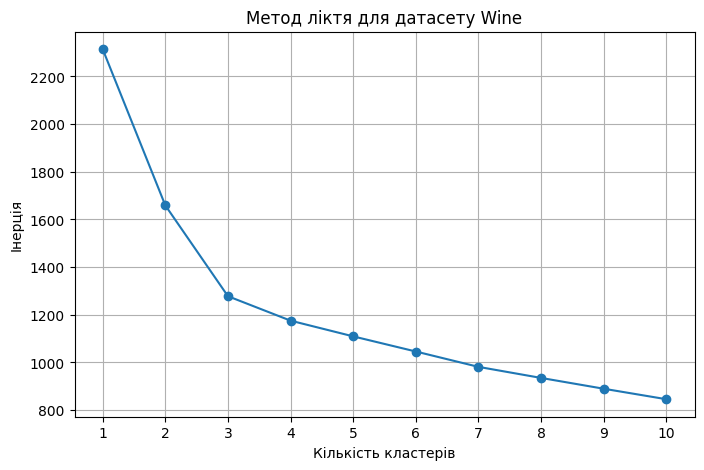

In [18]:
inertia_wine = []

K = range(1, 11)

for k in K:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_wine_scaled)
    inertia_wine.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(list(K), inertia_wine, marker='o')

plt.title("Метод ліктя для датасету Wine")
plt.xlabel("Кількість кластерів")
plt.ylabel("Інерція")
plt.xticks(list(K))
plt.grid(True)
plt.show()

Метод силуетів для Wine

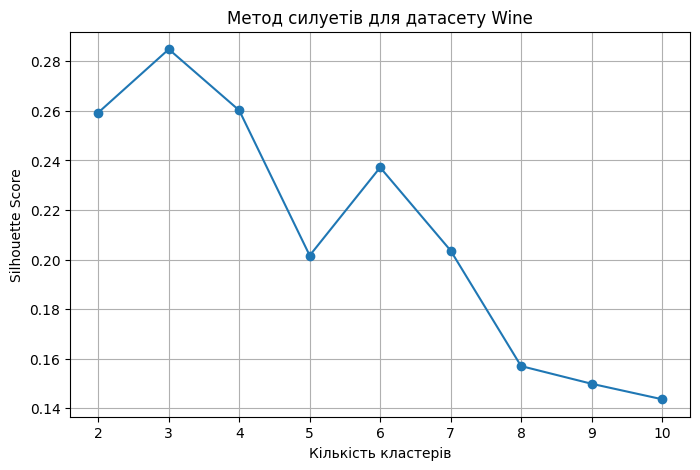

Оптимальна кількість кластерів за методом силуетів: 3


In [19]:
silhouette_scores_wine = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_wine_scaled)

    score = silhouette_score(X_wine_scaled, labels)
    silhouette_scores_wine.append(score)

plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores_wine,
    marker='o'
)

plt.title("Метод силуетів для датасету Wine")
plt.xlabel("Кількість кластерів")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

best_k_wine = range(2, 11)[
    np.argmax(silhouette_scores_wine)
]

print("Оптимальна кількість кластерів за методом силуетів:",
      best_k_wine)

Вибір кількості кластерів

In [20]:
optimal_k_wine = 3

print("Обрана кількість кластерів:", optimal_k_wine)
print("Оптимальна кількість за методом силуетів:", best_k_wine)
print("Обране значення можна додатково перевірити за графіком ліктя.")

Обрана кількість кластерів: 3
Оптимальна кількість за методом силуетів: 3
Обране значення можна додатково перевірити за графіком ліктя.


Кластеризація та візуалізація Wine

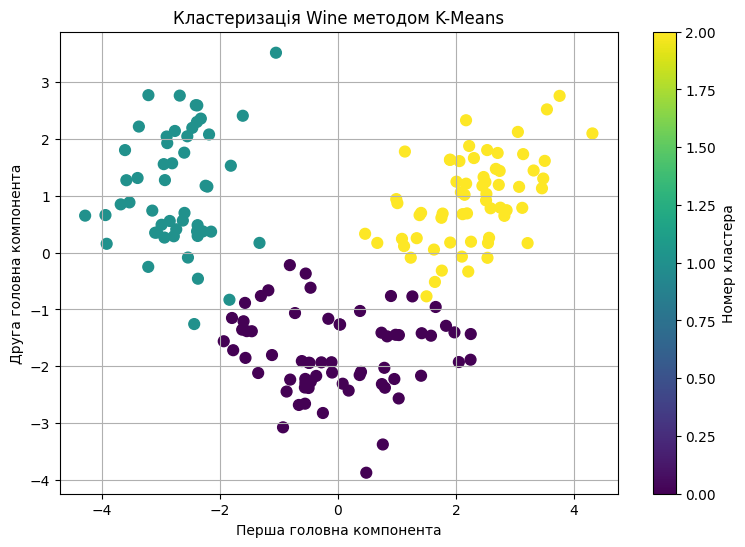

Кількість об'єктів у кожному кластері:
0    65
1    51
2    62
Name: count, dtype: int64


In [21]:
kmeans_wine = KMeans(
    n_clusters=optimal_k_wine,
    random_state=42,
    n_init=10
)

clusters_wine = kmeans_wine.fit_predict(X_wine_scaled)

pca_wine = PCA(n_components=2)

X_wine_pca = pca_wine.fit_transform(X_wine_scaled)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_wine_pca[:, 0],
    X_wine_pca[:, 1],
    c=clusters_wine,
    cmap='viridis',
    s=60
)

plt.title("Кластеризація Wine методом K-Means")
plt.xlabel("Перша головна компонента")
plt.ylabel("Друга головна компонента")
plt.colorbar(scatter, label="Номер кластера")
plt.grid(True)
plt.show()

print("Кількість об'єктів у кожному кластері:")
print(pd.Series(clusters_wine).value_counts().sort_index())

Додаткове порівняння кластерів із відомими класами

In [22]:
comparison = pd.crosstab(
    df['target'],
    clusters_wine,
    rownames=['Справжній клас'],
    colnames=['Кластер']
)

print("Порівняння справжніх класів із кластерами:")
display(comparison)

Порівняння справжніх класів із кластерами:


Кластер,0,1,2
Справжній клас,,,
0,0,0,59
1,65,3,3
2,0,48,0


Висновок: У ході виконання другого завдання було завантажено датасет Wine та проведено попередній аналіз даних. Переглянуто перші п'ять рядків, визначено розмір таблиці та типи даних. Перевірено наявність пропущених значень і дублікатів, а також отримано описову статистику.

Визначено, що задача прогнозування класу вина є задачею класифікації. Для розв'язання цієї задачі побудовано три моделі машинного навчання: логістичну регресію, випадковий ліс і метод опорних векторів. За допомогою GridSearchCV виконано підбір оптимальних параметрів, а якість моделей оцінено за метриками Accuracy, Precision, Recall та F1-score.

Для кластеризації використано алгоритм K-Means. Оптимальну кількість кластерів досліджено за допомогою методу ліктя та методу силуетів. Результати кластеризації візуалізовано у двовимірному просторі за допомогою PCA. Додатково порівняно отримані кластери з відомими класами датасету.

Отже, під час роботи було досліджено два підходи до машинного навчання: класифікацію з використанням відомих міток і кластеризацію без використання міток. Результати дали змогу порівняти якість класифікаційних моделей та оцінити структуру даних за допомогою кластеризації.